# Practical File 2 – Image Processing (Lab 9 & 10)

**Name:** Your Name

**Subject:** Image Processing

**Topics:** Edge Detection, Image Compression, Image Segmentation and Texture Analysis

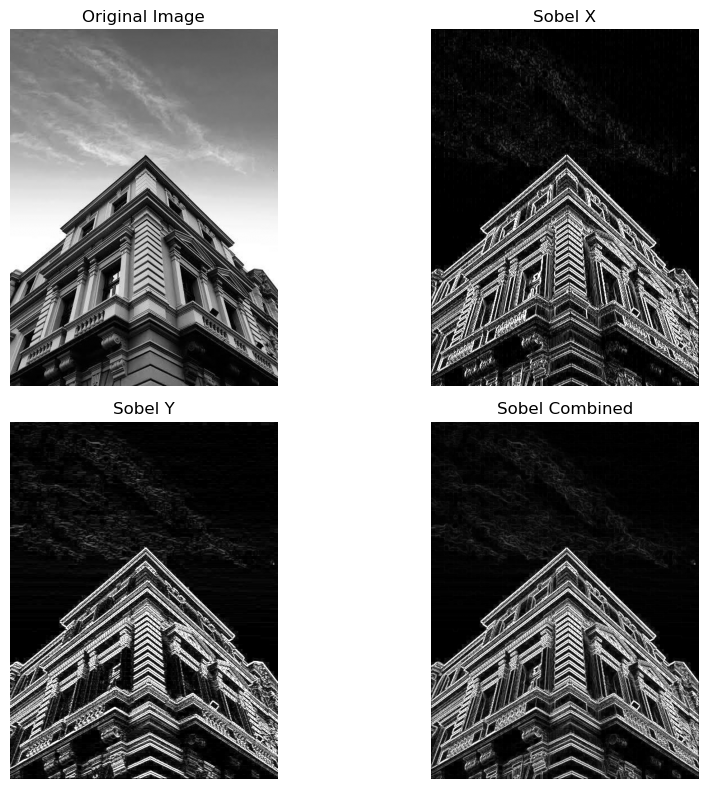

Sobel edge detection completed successfully!


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the image in grayscale
img = cv2.imread("building.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: building.jpg not found. Please upload the image.")
else:
    # 2. Apply Sobel operator in X direction
    sobel_x = cv2.Sobel(
        src=img,
        ddepth=cv2.CV_64F,
        dx=1,
        dy=0,
        ksize=3
    )

    # 3. Apply Sobel operator in Y direction
    sobel_y = cv2.Sobel(
        src=img,
        ddepth=cv2.CV_64F,
        dx=0,
        dy=1,
        ksize=3
    )

    # 4. Convert results into 8-bit images
    sobel_x_abs = cv2.convertScaleAbs(sobel_x)
    sobel_y_abs = cv2.convertScaleAbs(sobel_y)

    # 5. Combine X and Y edges
    sobel_combined = cv2.addWeighted(
        sobel_x_abs, 0.5,
        sobel_y_abs, 0.5,
        0
    )

    # 6. Display all results
    plt.figure(figsize=(10, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(sobel_x_abs, cmap="gray")
    plt.title("Sobel X")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(sobel_y_abs, cmap="gray")
    plt.title("Sobel Y")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(sobel_combined, cmap="gray")
    plt.title("Sobel Combined")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Sobel edge detection completed successfully!")

## Program 2 – Sobel and Laplacian Edge Detection

**Objective:** To detect image edges using Sobel and Laplacian operators.

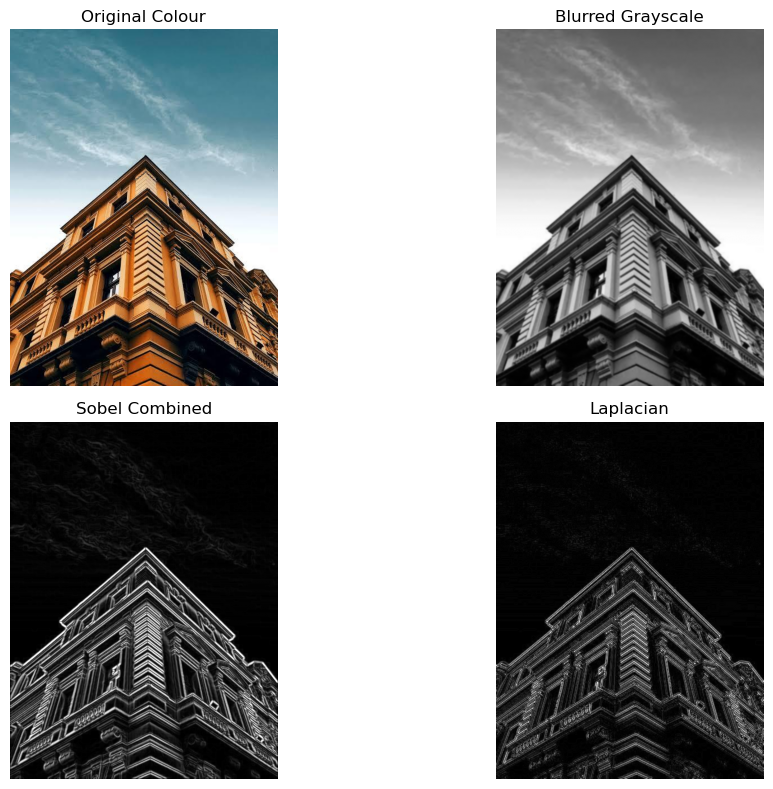

Sobel and Laplacian edge detection completed!


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the colour image
img = cv2.imread("building.jpg")

if img is None:
    print("Error: building.jpg not found. Please upload the image.")

else:
    # 2. Convert image to RGB and grayscale
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 3. Apply Gaussian Blur
    blurred = cv2.GaussianBlur(gray, (5, 5), 1)

    # 4. Apply Sobel operator in X and Y directions
    sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)

    # 5. Convert Sobel results to 8-bit images
    sobel_x_abs = cv2.convertScaleAbs(sobel_x)
    sobel_y_abs = cv2.convertScaleAbs(sobel_y)

    # 6. Combine Sobel edges
    sobel_combined = cv2.addWeighted(
        sobel_x_abs, 0.5,
        sobel_y_abs, 0.5,
        0
    )

    # 7. Apply Laplacian operator
    laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=3)
    laplacian_abs = cv2.convertScaleAbs(laplacian)

    # 8. Display results
    plt.figure(figsize=(12, 8))

    plt.subplot(2, 2, 1)
    plt.imshow(img_rgb)
    plt.title("Original Colour")
    plt.axis("off")

    plt.subplot(2, 2, 2)
    plt.imshow(blurred, cmap="gray")
    plt.title("Blurred Grayscale")
    plt.axis("off")

    plt.subplot(2, 2, 3)
    plt.imshow(sobel_combined, cmap="gray")
    plt.title("Sobel Combined")
    plt.axis("off")

    plt.subplot(2, 2, 4)
    plt.imshow(laplacian_abs, cmap="gray")
    plt.title("Laplacian")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Sobel and Laplacian edge detection completed!")

## Program 3 – Gradient Magnitude, Direction and Laplacian Thresholding

**Objective:** To calculate gradient magnitude and direction using Sobel operators and detect edges using the Laplacian operator.

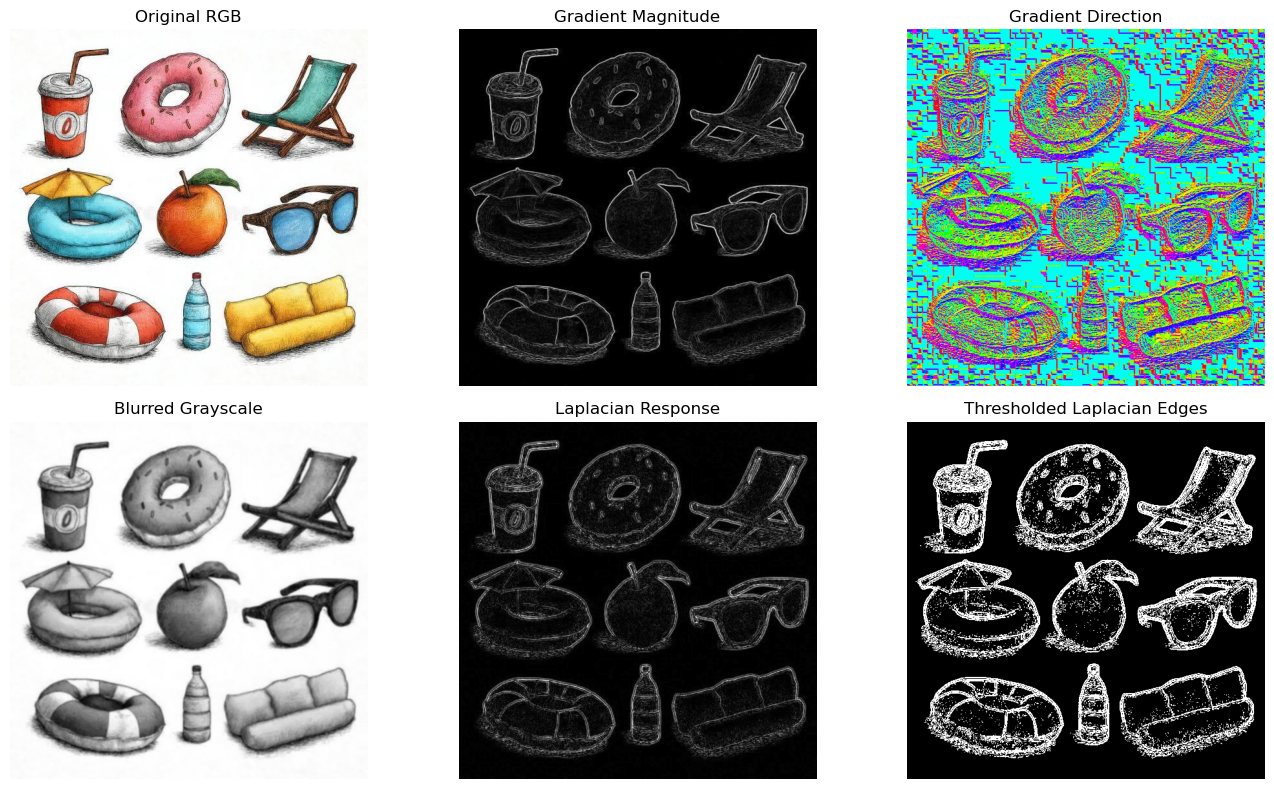

Gradient and Laplacian processing completed!


In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the image
img = cv2.imread("objects.png")

if img is None:
    print("Error: objects.png not found. Please upload the image.")

else:
    # 2. Convert image into RGB and grayscale
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 3. Apply Sobel operators
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

    # 4. Calculate gradient magnitude and direction
    grad_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
    grad_direction = np.arctan2(sobel_y, sobel_x)

    # 5. Normalize gradient magnitude
    grad_magnitude_norm = cv2.normalize(
        grad_magnitude, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

    # 6. Normalize gradient direction
    grad_direction_norm = (grad_direction + np.pi) / (2 * np.pi)
    grad_direction_norm = (grad_direction_norm * 255).astype(np.uint8)

    # 7. Apply Gaussian Blur
    blurred = cv2.GaussianBlur(gray, (5, 5), 1)

    # 8. Apply Laplacian operator
    laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=3)
    laplacian_abs = cv2.convertScaleAbs(laplacian)

    # 9. Apply thresholding
    _, laplacian_thresh = cv2.threshold(
        laplacian_abs, 30, 255, cv2.THRESH_BINARY
    )

    # 10. Display all results
    plt.figure(figsize=(14, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(img_rgb)
    plt.title("Original RGB")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(grad_magnitude_norm, cmap="gray")
    plt.title("Gradient Magnitude")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(grad_direction_norm, cmap="hsv")
    plt.title("Gradient Direction")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(blurred, cmap="gray")
    plt.title("Blurred Grayscale")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(laplacian_abs, cmap="gray")
    plt.title("Laplacian Response")
    plt.axis("off")

    plt.subplot(2, 3, 6)
    plt.imshow(laplacian_thresh, cmap="gray")
    plt.title("Thresholded Laplacian Edges")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Gradient and Laplacian processing completed!")

## Program 4 – Run-Length Encoding (RLE)

**Objective:** To perform basic image compression using Run-Length Encoding.

Original number of pixels: 122500
Number of encoded runs: 96831
First 20 encoded values:
[(np.uint8(17), 1), (np.uint8(18), 4), (np.uint8(17), 1), (np.uint8(16), 1), (np.uint8(15), 1), (np.uint8(14), 1), (np.uint8(13), 1), (np.uint8(12), 1), (np.uint8(11), 4), (np.uint8(12), 1), (np.uint8(9), 3), (np.uint8(10), 2), (np.uint8(11), 6), (np.uint8(12), 2), (np.uint8(13), 3), (np.uint8(14), 4), (np.uint8(13), 4), (np.uint8(15), 3), (np.uint8(14), 2), (np.uint8(13), 2)]


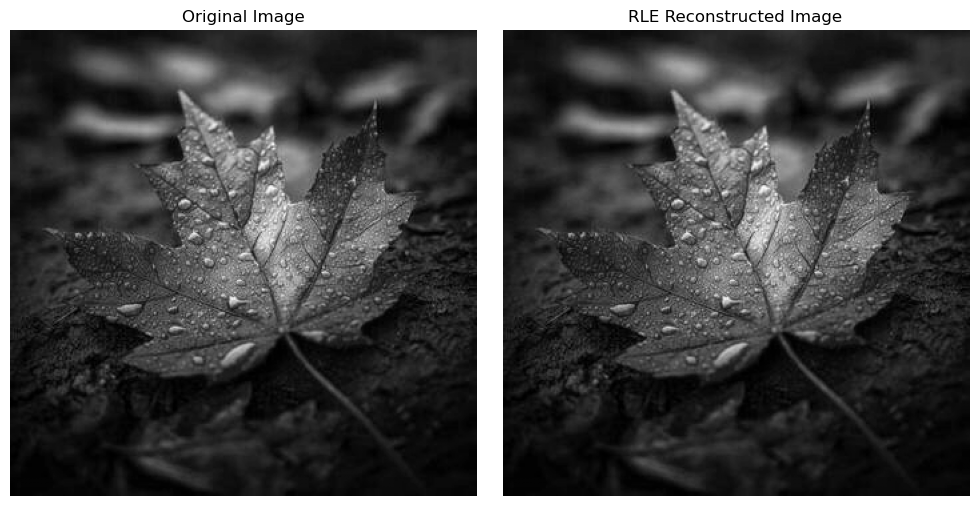

Run-Length Encoding completed successfully!


In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Read the image in grayscale
img = cv2.imread("leaf.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: leaf.png not found. Please upload the image.")

else:
    # 2. Convert image into a one-dimensional array
    flat = img.flatten()

    # 3. Perform Run-Length Encoding
    encoded = []

    count = 1

    for i in range(1, len(flat)):
        if flat[i] == flat[i - 1]:
            count += 1
        else:
            encoded.append((flat[i - 1], count))
            count = 1

    # Add the final run
    encoded.append((flat[-1], count))

    # 4. Print compression information
    print("Original number of pixels:", len(flat))
    print("Number of encoded runs:", len(encoded))
    print("First 20 encoded values:")
    print(encoded[:20])

    # 5. Reconstruct the image
    reconstructed = []

    for value, count in encoded:
        reconstructed.extend([value] * count)

    reconstructed = np.array(reconstructed, dtype=np.uint8)
    reconstructed = reconstructed.reshape(img.shape)

    # 6. Display original and reconstructed images
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(reconstructed, cmap="gray")
    plt.title("RLE Reconstructed Image")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Run-Length Encoding completed successfully!")

## Program 5 – Huffman Coding

**Objective:** To perform image compression using Huffman Coding and calculate the compression ratio.

Original bits: 980000
Compressed bits: 816940
Number of unique pixel values: 197
Compression Ratio: 1.199598501725953


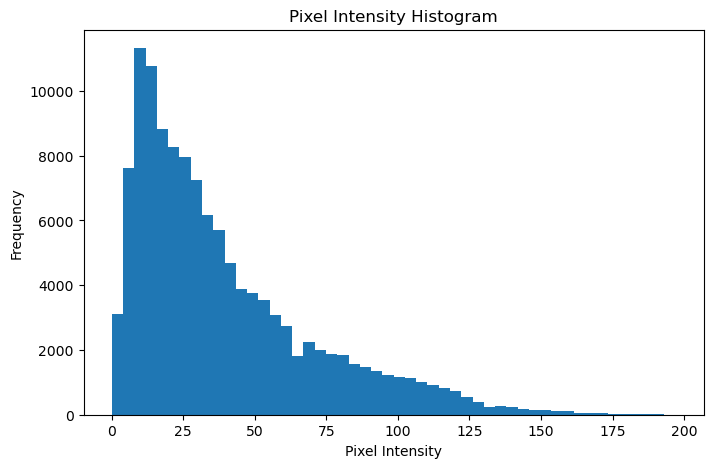

Huffman Coding completed successfully!


In [14]:
import cv2
import numpy as np
import heapq
import matplotlib.pyplot as plt
from itertools import count

# 1. Load image in grayscale
img = cv2.imread("leaf.png", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: leaf.png not found. Please upload the image.")

else:
    # 2. Flatten the image
    flat = img.flatten()

    # 3. Calculate frequency of each pixel value
    freq = {}

    for pixel in flat:
        pixel = int(pixel)
        freq[pixel] = freq.get(pixel, 0) + 1

    # 4. Build Huffman Tree
    unique_id = count()
    heap = []

    for symbol, weight in freq.items():
        heapq.heappush(heap, (weight, next(unique_id), symbol))

    while len(heap) > 1:
        weight1, id1, left = heapq.heappop(heap)
        weight2, id2, right = heapq.heappop(heap)

        new_node = (left, right)

        heapq.heappush(
            heap,
            (weight1 + weight2, next(unique_id), new_node)
        )

    # 5. Generate Huffman codes
    huffman_codes = {}

    def generate_codes(node, code=""):
        if isinstance(node, int):
            huffman_codes[node] = code if code else "0"
        else:
            left, right = node
            generate_codes(left, code + "0")
            generate_codes(right, code + "1")

    generate_codes(heap[0][2])

    # 6. Encode the image
    encoded = "".join(
        huffman_codes[int(pixel)] for pixel in flat
    )

    # 7. Calculate compression information
    original_bits = len(flat) * 8
    compressed_bits = len(encoded)

    print("Original bits:", original_bits)
    print("Compressed bits:", compressed_bits)
    print("Number of unique pixel values:", len(freq))
    print("Compression Ratio:", original_bits / compressed_bits)

    # 8. Display pixel intensity histogram
    plt.figure(figsize=(8, 5))

    plt.hist(flat, bins=50)
    plt.title("Pixel Intensity Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")

    plt.show()

    print("Huffman Coding completed successfully!")

## Program 6 – JPEG-Style Image Compression

**Objective:** To perform JPEG-style image compression using DCT and quantization and calculate MSE and PSNR.

Mean Squared Error (MSE): 76.81652
Peak Signal-to-Noise Ratio (PSNR): 29.276257222405732 dB


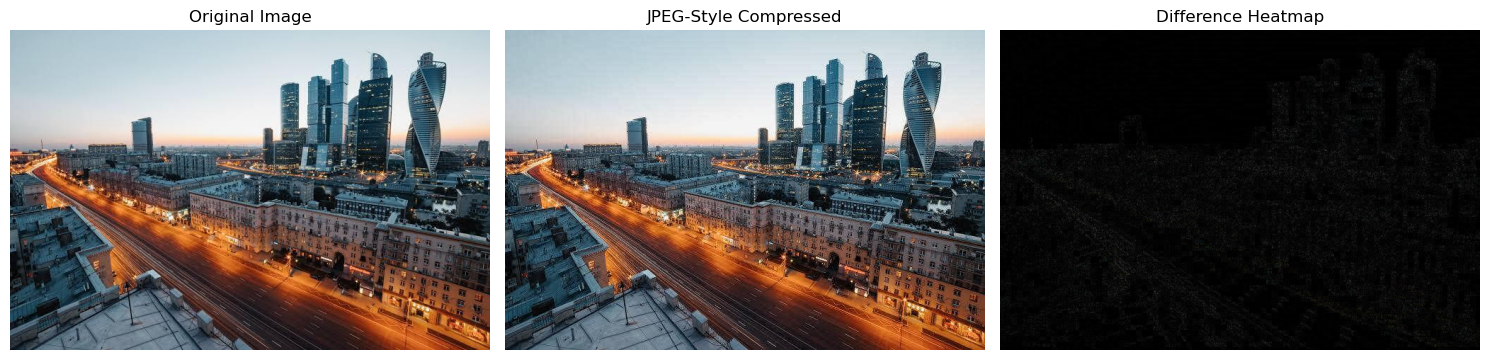

JPEG-style compression completed successfully!
Compressed image saved as compressed_city.jpg


In [15]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load the colour image
img = cv2.imread("city.jpg")

if img is None:
    print("Error: city.jpg not found. Please check the filename.")

else:
    # 2. Convert image from BGR to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # 3. Convert RGB image to YCrCb colour space
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)

    Y, Cr, Cb = cv2.split(ycc)

    # 4. Define JPEG quantization matrix
    Q = np.array([
        [16, 11, 10, 16, 24, 40, 51, 61],
        [12, 12, 14, 19, 26, 58, 60, 55],
        [14, 13, 16, 24, 40, 57, 69, 56],
        [14, 17, 22, 29, 51, 87, 80, 62],
        [18, 22, 37, 56, 68, 109, 103, 77],
        [24, 35, 55, 64, 81, 104, 113, 92],
        [49, 64, 78, 87, 103, 121, 120, 101],
        [72, 92, 95, 98, 112, 100, 103, 99]
    ], dtype=np.float32)

    # 5. Convert Y channel to float
    Y = np.float32(Y)

    # Pad image dimensions to multiples of 8
    h, w = Y.shape
    pad_h = (8 - h % 8) % 8
    pad_w = (8 - w % 8) % 8

    Y_padded = cv2.copyMakeBorder(
        Y, 0, pad_h, 0, pad_w, cv2.BORDER_REFLECT
    )

    # 6. Apply DCT and quantization on 8x8 blocks
    compressed_Y = np.zeros_like(Y_padded)

    for i in range(0, Y_padded.shape[0], 8):
        for j in range(0, Y_padded.shape[1], 8):

            block = Y_padded[i:i+8, j:j+8]

            dct_block = cv2.dct(block)

            quantized = np.round(dct_block / Q)

            dequantized = quantized * Q

            idct_block = cv2.idct(dequantized)

            compressed_Y[i:i+8, j:j+8] = idct_block

    # 7. Remove padding and bring values into valid range
    compressed_Y = compressed_Y[:h, :w]
    compressed_Y = np.clip(compressed_Y, 0, 255).astype(np.uint8)

    # 8. Merge the channels
    compressed_ycc = cv2.merge([compressed_Y, Cr, Cb])

    # 9. Convert back to RGB
    compressed_rgb = cv2.cvtColor(
        compressed_ycc, cv2.COLOR_YCrCb2RGB
    )

    # 10. Calculate image difference
    difference = cv2.absdiff(img, compressed_rgb)

    # 11. Calculate MSE and PSNR
    mse = np.mean(
        (img.astype(np.float32) - compressed_rgb.astype(np.float32)) ** 2
    )

    psnr = cv2.PSNR(img, compressed_rgb)

    print("Mean Squared Error (MSE):", mse)
    print("Peak Signal-to-Noise Ratio (PSNR):", psnr, "dB")

    # 12. Display results
    plt.figure(figsize=(15, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(compressed_rgb)
    plt.title("JPEG-Style Compressed")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(difference)
    plt.title("Difference Heatmap")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    # 13. Save compressed image
    cv2.imwrite(
        "compressed_city.jpg",
        cv2.cvtColor(compressed_rgb, cv2.COLOR_RGB2BGR)
    )

    print("JPEG-style compression completed successfully!")
    print("Compressed image saved as compressed_city.jpg")

## Program 7 – Image Statistics, Histogram and Otsu Segmentation

**Objective:** To calculate image statistics, display its histogram and perform Otsu threshold segmentation.

Mean intensity: 103.48829836829837
Standard deviation: 62.87494035101804
Otsu threshold value: 117.0


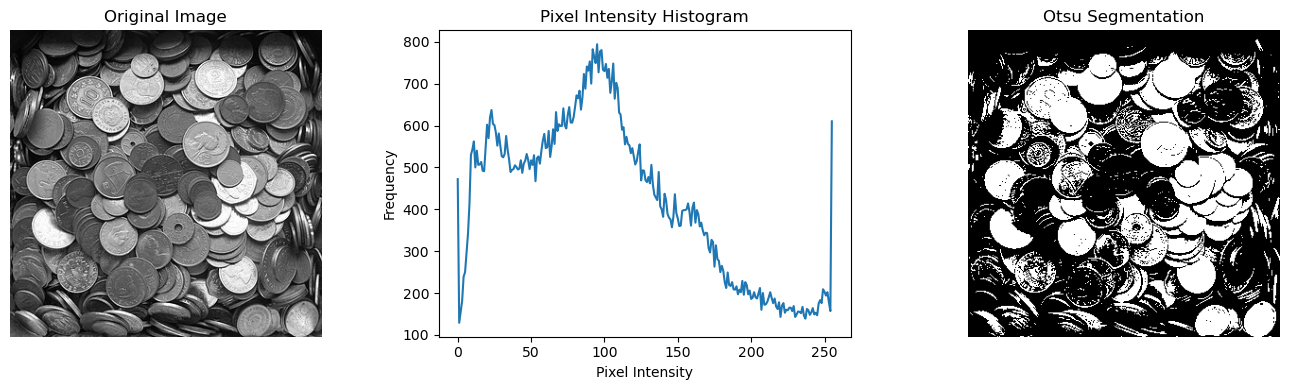

Image analysis and Otsu segmentation completed!


In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load image in grayscale
img = cv2.imread("coins.jpg", cv2.IMREAD_GRAYSCALE)

if img is None:
    print("Error: coins.jpg not found. Please upload the image.")

else:
    # 2. Calculate mean and standard deviation
    mean_intensity = np.mean(img)
    std_intensity = np.std(img)

    print("Mean intensity:", mean_intensity)
    print("Standard deviation:", std_intensity)

    # 3. Calculate image histogram
    hist = cv2.calcHist([img], [0], None, [256], [0, 256])

    # 4. Apply Otsu's threshold segmentation
    threshold_value, binary = cv2.threshold(
        img,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    print("Otsu threshold value:", threshold_value)

    # 5. Display original, histogram and segmented image
    plt.figure(figsize=(14, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap="gray")
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.plot(hist)
    plt.title("Pixel Intensity Histogram")
    plt.xlabel("Pixel Intensity")
    plt.ylabel("Frequency")
    plt.grid(False)

    plt.subplot(1, 3, 3)
    plt.imshow(binary, cmap="gray")
    plt.title("Otsu Segmentation")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Image analysis and Otsu segmentation completed!")

## Program 8 – GLCM Texture Features and K-Means Segmentation

**Objective:** To extract texture features using GLCM and perform image segmentation using K-Means clustering.

Contrast: 83.9095109867845
Energy: 0.020538510824570512
Homogeneity: 0.3254831203185874


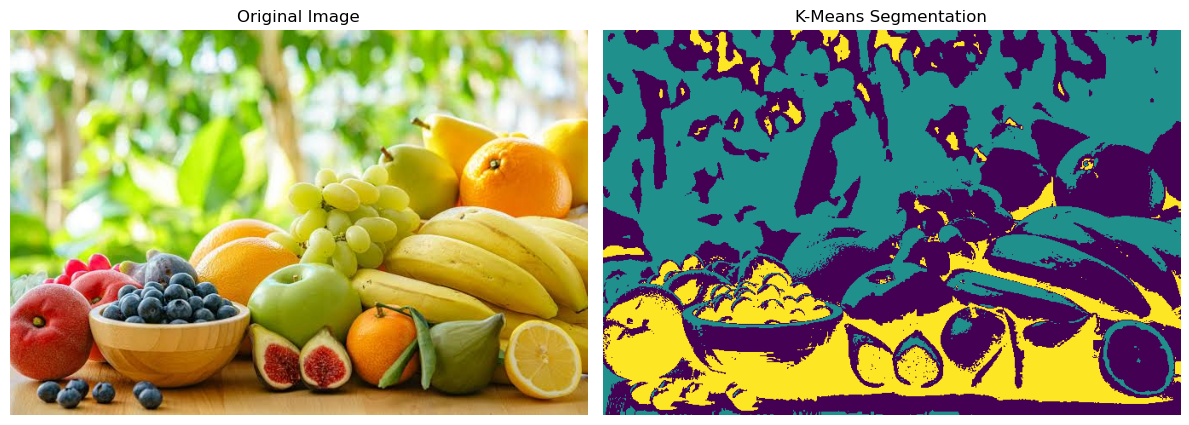

GLCM and K-Means segmentation completed!


In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops

# 1. Load the image
img = cv2.imread("fruits.png")

if img is None:
    print("Error: fruits.png not found. Please upload the image.")

else:
    # 2. Convert image into grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 3. Calculate GLCM matrix
    glcm = graycomatrix(
        gray,
        distances=[1],
        angles=[0],
        symmetric=True,
        normed=True
    )

    # 4. Extract texture features
    contrast = graycoprops(glcm, "contrast")[0, 0]
    energy = graycoprops(glcm, "energy")[0, 0]
    homogeneity = graycoprops(glcm, "homogeneity")[0, 0]

    print("Contrast:", contrast)
    print("Energy:", energy)
    print("Homogeneity:", homogeneity)

    # 5. Prepare pixels for K-Means clustering
    pixels = gray.reshape((-1, 1)).astype(np.float32)

    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        20,
        1.0
    )

    # 6. Apply K-Means with 3 clusters
    k = 3

    _, labels, centers = cv2.kmeans(
        pixels,
        k,
        None,
        criteria,
        10,
        cv2.KMEANS_PP_CENTERS
    )

    # 7. Reshape labels into image dimensions
    segmented = labels.reshape(gray.shape)

    # 8. Display original and segmented images
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(segmented, cmap="viridis")
    plt.title("K-Means Segmentation")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("GLCM and K-Means segmentation completed!")

## Program 9 – Multi-Feature K-Means Image Segmentation

**Objective:** To perform image segmentation using intensity, Sobel magnitude and local texture features.

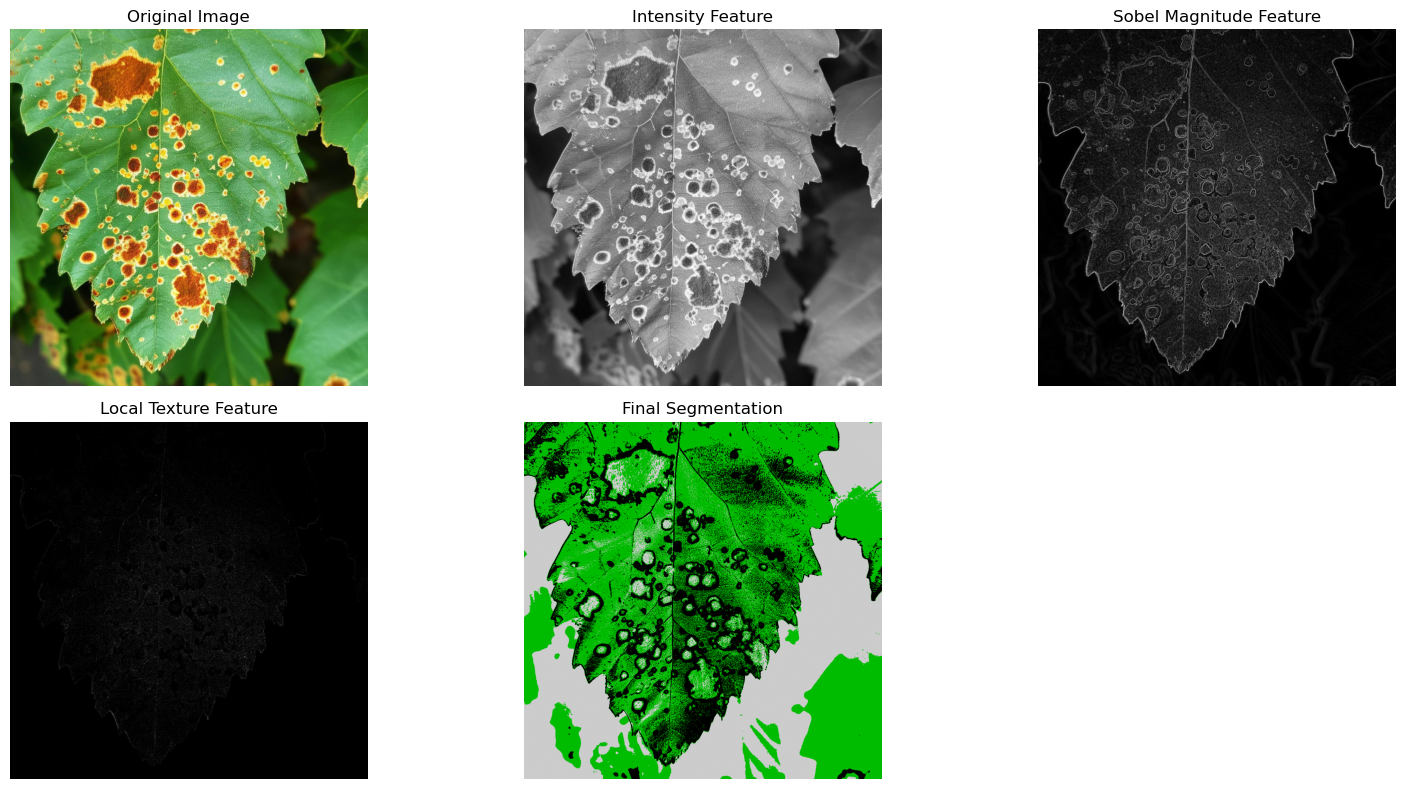

Multi-feature K-Means segmentation completed!


In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load image
img = cv2.imread("leaf_disease.jpg")

if img is None:
    print("Error: leaf_disease.jpg not found. Please upload the image.")

else:
    # 2. Convert image into RGB and grayscale
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # 3. Calculate Sobel magnitude
    sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
    sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

    sobel_mag = np.sqrt(sobel_x**2 + sobel_y**2)

    sobel_mag = cv2.normalize(
        sobel_mag, None, 0, 255, cv2.NORM_MINMAX
    )

    # 4. Calculate local texture variance
    kernel = np.ones((3, 3), np.float32) / 9.0

    blur = cv2.filter2D(gray, -1, kernel)

    local_var = (gray.astype(np.float32) - blur.astype(np.float32))**2

    local_var = cv2.normalize(
        local_var, None, 0, 255, cv2.NORM_MINMAX
    )

    # 5. Prepare three features
    feature_vector = np.stack([
        gray,
        sobel_mag.astype(np.uint8),
        local_var.astype(np.uint8)
    ], axis=2)

    # 6. Flatten feature vector
    h, w = gray.shape

    fv_flat = feature_vector.reshape((-1, 3)).astype(np.float32)

    # 7. Apply K-Means clustering
    criteria = (
        cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER,
        30,
        1.0
    )

    k = 3

    _, labels, centers = cv2.kmeans(
        fv_flat,
        k,
        None,
        criteria,
        10,
        cv2.KMEANS_PP_CENTERS
    )

    # 8. Reshape segmentation labels
    segmented = labels.reshape((h, w))

    # 9. Display results
    plt.figure(figsize=(16, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(rgb)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(gray, cmap="gray")
    plt.title("Intensity Feature")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(sobel_mag, cmap="gray")
    plt.title("Sobel Magnitude Feature")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(local_var, cmap="gray")
    plt.title("Local Texture Feature")
    plt.axis("off")

    plt.subplot(2, 3, 5)
    plt.imshow(segmented, cmap="nipy_spectral")
    plt.title("Final Segmentation")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Multi-feature K-Means segmentation completed!")